In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

In [3]:
adult_df=pd.read_csv('/content/drive/MyDrive/AI ML-Course/AI ML-Dataset/adult_dataset.csv')

In [4]:
pd.set_option('display.max_columns',None)

In [5]:
adult_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             46400 non-null  float64
 1   workclass       45480 non-null  object 
 2   fnlwgt          48842 non-null  int64  
 3   education       48842 non-null  object 
 4   education-num   48842 non-null  int64  
 5   marital-status  48842 non-null  object 
 6   occupation      45485 non-null  object 
 7   relationship    48842 non-null  object 
 8   race            48842 non-null  object 
 9   sex             48842 non-null  object 
 10  capital-gain    48842 non-null  int64  
 11  capital-loss    48842 non-null  int64  
 12  hours-per-week  46400 non-null  float64
 13  native-country  46137 non-null  object 
 14  income          48842 non-null  object 
dtypes: float64(2), int64(4), object(9)
memory usage: 5.6+ MB


In [6]:
adult_df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,46400.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,46400.000000
mean,38.679116,1.896641e+05,10.078089,1079.067626,87.502314,40.448599
std,13.952954,1.056040e+05,2.570973,7452.019058,403.004552,12.646992
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,255.000000,1.490400e+06,16.000000,99999.000000,4356.000000,250.000000


In [7]:
adult_df.isna().sum()

,0
age,2442
workclass,3362
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,3357
relationship,0
race,0
sex,0


In [8]:
adult_df['income'].value_counts()
adult_df['income'].unique()

array(['<=50K', '>50K', '<=50K.', '>50K.'], dtype=object)

In [9]:
adult_df['income'] = adult_df['income'].str.strip().str.rstrip('.')

In [10]:
adult_df['income'].unique()

array(['<=50K', '>50K'], dtype=object)

In [11]:
#Duplicate checking
adult_df.duplicated().sum()

np.int64(25)

In [12]:
#Drop duplicates
adult_df=adult_df.drop_duplicates().reset_index(drop=True)

In [13]:
#Target selection
X=adult_df.drop(columns=['income'],axis=1)
y=adult_df['income']

In [14]:
#Train-Test-Split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,stratify=y)

In [15]:
#Seperating numerical and categorical columns
num_col=X_train.select_dtypes(include='number').columns
cat_col=X_train.select_dtypes(include='object').columns

In [16]:
num_col

Index(['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss',
       'hours-per-week'],
      dtype='object')

In [17]:
cat_col

Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country'],
      dtype='object')

###Numerical Data Handling

In [18]:
adult_df[num_col].isna().sum()

,0
age,2442
fnlwgt,0
education-num,0
capital-gain,0
capital-loss,0
hours-per-week,2442


In [19]:
(adult_df.isna().sum())/len(adult_df)*100

,0
age,5.002356
workclass,6.886945
fnlwgt,0.000000
education,0.000000
education-num,0.000000
marital-status,0.000000
occupation,6.876703
relationship,0.000000
race,0.000000
sex,0.000000


In [20]:
#Handle missing values in numerical columns by imputer(median)
num_imputer = SimpleImputer(strategy='median')

X_train_num = num_imputer.fit_transform(X_train[num_col])
X_test_num = num_imputer.transform(X_test[num_col])

#Check missing values
np.isnan(X_train_num).sum()

np.int64(0)

In [21]:
#Using Scaling
scaler=StandardScaler()

X_train_num_scaled=scaler.fit_transform(X_train_num)
X_test_num_scaled=scaler.transform(X_test_num)

In [22]:
np.isnan(X_train_num_scaled).sum()

np.int64(0)

In [23]:
#Conveting scaled columns into pd
X_train_num_df = pd.DataFrame(
    X_train_num_scaled,
    columns=num_col,
    index=X_train.index)

X_test_num_df = pd.DataFrame(
    X_test_num_scaled,
    columns=num_col,
    index=X_test.index)

In [24]:
X_train_num_df.isna().sum()

,0
age,0
fnlwgt,0
education-num,0
capital-gain,0
capital-loss,0
hours-per-week,0


###Categorical Data Processing

In [25]:
#Handle missing values by imputer(most_frequent)
for col in cat_col:
  X_train[col]=X_train[col].astype(str).str.strip().replace({'?':np.nan,'nan':np.nan})
  X_test[col]=X_test[col].astype(str).str.strip().replace({'?':np.nan,'nan':np.nan})

cat_imputer=SimpleImputer(strategy='most_frequent')


X_train_cat=cat_imputer.fit_transform(X_train[cat_col])
X_test_cat=cat_imputer.transform(X_test[cat_col])

X_train_cat_pd=pd.DataFrame(
    X_train_cat,
    columns=cat_col,
    index=X_train.index
)
X_test_cat_pd=pd.DataFrame(
    X_test_cat,
    columns=cat_col,
    index=X_test.index
)

In [26]:
#Convert into DataFrame


In [27]:
X_train_cat_pd['workclass'].unique()

array(['Private', 'State-gov', 'Self-emp-inc', 'Federal-gov',
       'Self-emp-not-inc', 'Local-gov', 'Without-pay', 'Never-worked'],
      dtype=object)

In [28]:
for col in cat_col:
  print(f'{col}: ==> {adult_df[col].unique()}')

workclass: ==> ['State-gov' 'Self-emp-not-inc' 'Private' 'Federal-gov' nan 'Local-gov'
 '?' 'Self-emp-inc' 'Without-pay' 'Never-worked']
education: ==> ['Bachelors' 'HS-grad' '11th' 'Masters' '9th' 'Some-college' 'Assoc-acdm'
 'Assoc-voc' '7th-8th' 'Doctorate' 'Prof-school' '5th-6th' '10th'
 '1st-4th' 'Preschool' '12th']
marital-status: ==> ['Never-married' 'Married-civ-spouse' 'Divorced' 'Married-spouse-absent'
 'Separated' 'Married-AF-spouse' 'Widowed']
occupation: ==> ['Adm-clerical' 'Exec-managerial' 'Handlers-cleaners' 'Prof-specialty'
 'Other-service' 'Sales' 'Craft-repair' 'Transport-moving'
 'Farming-fishing' 'Machine-op-inspct' 'Tech-support' nan
 'Protective-serv' '?' 'Armed-Forces' 'Priv-house-serv']
relationship: ==> ['Not-in-family' 'Husband' 'Wife' 'Own-child' 'Unmarried' 'Other-relative']
race: ==> ['White' 'Black' 'Asian-Pac-Islander' 'Amer-Indian-Eskimo' 'Other']
sex: ==> ['Male' 'Female']
native-country: ==> [nan 'United-States' 'Cuba' 'Jamaica' 'India' '?' 'Mexico' '

In [29]:
#Convert cat_col using OneHotEncoder
one_hot=OneHotEncoder(handle_unknown='ignore', sparse_output=False)

X_train_one_hot=one_hot.fit_transform(X_train_cat_pd[cat_col])
X_train_one_hot_encoded=pd.DataFrame(
    X_train_one_hot,
    columns=one_hot.get_feature_names_out(cat_col),
    index=X_train_cat_pd.index
)

X_test_one_hot=one_hot.transform(X_test_cat_pd[cat_col])
X_test_one_hot_encoded=pd.DataFrame(
    X_test_one_hot,
    columns=one_hot.get_feature_names_out(cat_col),
    index=X_test_cat_pd.index
)

In [30]:
# Verify there are 0 missing values in both parts before combining
print("Numeric NaNs:\n", X_train_num_df.isna().sum())
print("Categorical NaNs:", X_train_one_hot_encoded.isna().sum().sum())


Numeric NaNs:
 age               0
fnlwgt            0
education-num     0
capital-gain      0
capital-loss      0
hours-per-week    0
dtype: int64
Categorical NaNs: 0


In [31]:
#concat numerical columns and categorical columns
X_train_final=pd.concat([X_train_num_df.reset_index(drop=True),X_train_one_hot_encoded.reset_index(drop=True)],axis=1)
X_test_final=pd.concat([X_test_num_df.reset_index(drop=True),X_test_one_hot_encoded.reset_index(drop=True)],axis=1)

In [32]:
X_train_final

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Without-pay,education_10th,education_11th,education_12th,education_1st-4th,education_5th-6th,education_7th-8th,education_9th,education_Assoc-acdm,education_Assoc-voc,education_Bachelors,education_Doctorate,education_HS-grad,education_Masters,education_Preschool,education_Prof-school,education_Some-college,marital-status_Divorced,marital-status_Married-AF-spouse,marital-status_Married-civ-spouse,marital-status_Married-spouse-absent,marital-status_Never-married,marital-status_Separated,marital-status_Widowed,occupation_Adm-clerical,occupation_Armed-Forces,occupation_Craft-repair,occupation_Exec-managerial,occupation_Farming-fishing,occupation_Handlers-cleaners,occupation_Machine-op-inspct,occupation_Other-service,occupation_Priv-house-serv,occupation_Prof-specialty,occupation_Protective-serv,occupation_Sales,occupation_Tech-support,occupation_Transport-moving,relationship_Husband,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,race_Amer-Indian-Eskimo,race_Asian-Pac-Islander,race_Black,race_Other,race_White,sex_Female,sex_Male,native-country_Cambodia,native-country_Canada,native-country_China,native-country_Columbia,native-country_Cuba,native-country_Dominican-Republic,native-country_Ecuador,native-country_El-Salvador,native-country_England,native-country_France,native-country_Germany,native-country_Greece,native-country_Guatemala,native-country_Haiti,native-country_Holand-Netherlands,native-country_Honduras,native-country_Hong,native-country_Hungary,native-country_India,native-country_Iran,native-country_Ireland,native-country_Italy,native-country_Jamaica,native-country_Japan,native-country_Laos,native-country_Mexico,native-country_Nicaragua,native-country_Outlying-US(Guam-USVI-etc),native-country_Peru,native-country_Philippines,native-country_Poland,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,1.055482,-0.055203,-1.195991,-0.144745,-0.215953,0.610272,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.614893,-0.787043,-1.195991,-0.144745,-0.215953,0.772237,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,0.100873,0.149077,1.524731,-0.144745,-0.215953,0.772237,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,-0.486579,0.152568,-0.029967,-0.144745,-0.215953,0.772237,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0

In [33]:
X_test_final

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Without-pay,education_10th,education_11th,education_12th,education_1st-4th,education_5th-6th,education_7th-8th,education_9th,education_Assoc-acdm,education_Assoc-voc,education_Bachelors,education_Doctorate,education_HS-grad,education_Masters,education_Preschool,education_Prof-school,education_Some-college,marital-status_Divorced,marital-status_Married-AF-spouse,marital-status_Married-civ-spouse,marital-status_Married-spouse-absent,marital-status_Never-married,marital-status_Separated,marital-status_Widowed,occupation_Adm-clerical,occupation_Armed-Forces,occupation_Craft-repair,occupation_Exec-managerial,occupation_Farming-fishing,occupation_Handlers-cleaners,occupation_Machine-op-inspct,occupation_Other-service,occupation_Priv-house-serv,occupation_Prof-specialty,occupation_Protective-serv,occupation_Sales,occupation_Tech-support,occupation_Transport-moving,relationship_Husband,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,race_Amer-Indian-Eskimo,race_Asian-Pac-Islander,race_Black,race_Other,race_White,sex_Female,sex_Male,native-country_Cambodia,native-country_Canada,native-country_China,native-country_Columbia,native-country_Cuba,native-country_Dominican-Republic,native-country_Ecuador,native-country_El-Salvador,native-country_England,native-country_France,native-country_Germany,native-country_Greece,native-country_Guatemala,native-country_Haiti,native-country_Holand-Netherlands,native-country_Honduras,native-country_Hong,native-country_Hungary,native-country_India,native-country_Iran,native-country_Ireland,native-country_Italy,native-country_Jamaica,native-country_Japan,native-country_Laos,native-country_Mexico,native-country_Nicaragua,native-country_Outlying-US(Guam-USVI-etc),native-country_Peru,native-country_Philippines,native-country_Poland,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,-0.119422,-1.297060,-1.195991,-0.144745,-0.215953,-2.062156,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,-1.294325,-0.841108,0.358708,0.141949,-0.215953,-0.037589,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,-1.441188,0.318367,-0.029967,-0.144745,-0.215953,-0.847416,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,-0.853736,0.729205,-0.418642,0.312067,-0.215953,-0.037589,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.

In [34]:
y_train.value_counts()

,count
income,
<=50K,29704
>50K,9349


In [35]:
#Target Encode

le=LabelEncoder()

y_train_encode=le.fit_transform(y_train)
y_test_encode=le.transform(y_test)



In [37]:
y_train_df=pd.DataFrame(
    y_train_encode,
    columns=['income'],
    index=y_train.index
)
y_test_df=pd.DataFrame(
    y_test_encode,
    columns=['income'],
    index=y_test.index
)

In [38]:
#Handle class imbalance by SMOTE
smote=SMOTE(random_state=42)

X_train_imbalance,y_train_imbalance=smote.fit_resample(X_train_final,y_train_encode)

In [39]:
y_train_df=pd.DataFrame(
    y_train_imbalance,
    columns=['income'],
)

In [40]:
y_train_df.value_counts()

,count
income,
0,29704
1,29704


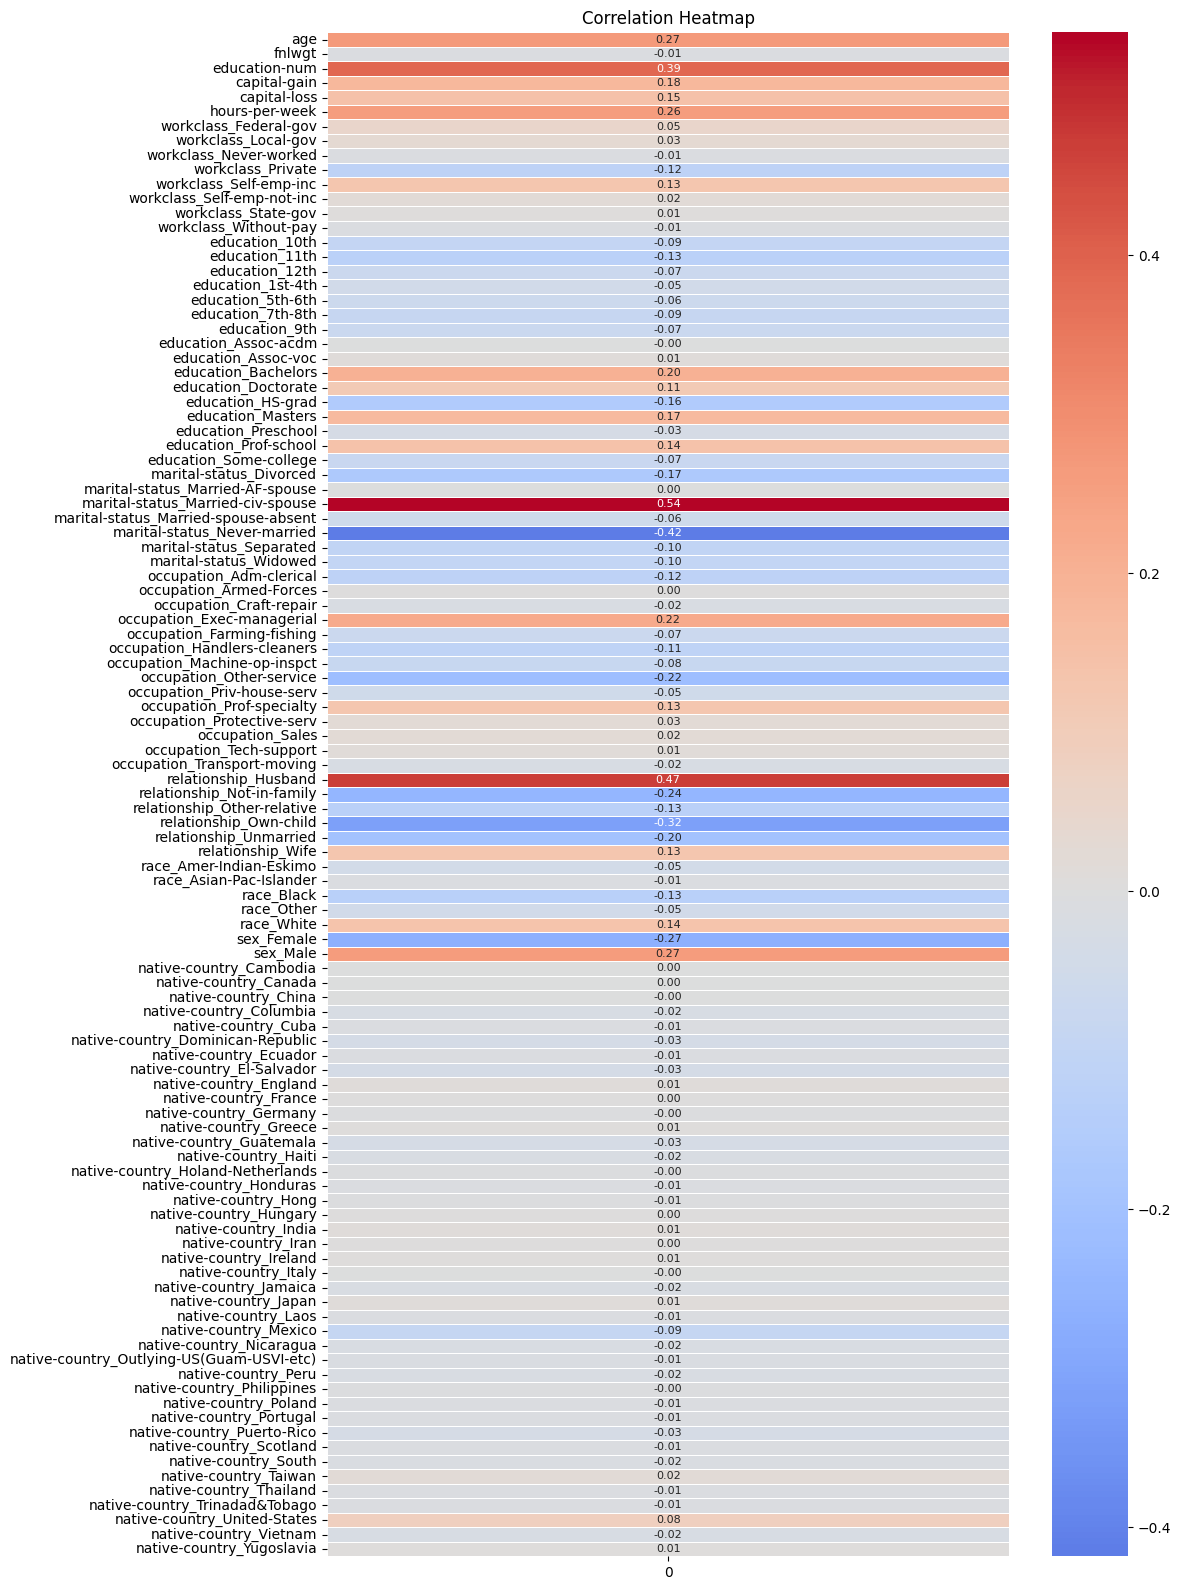

In [50]:
#Correlation Heatmap
corr=X_train_imbalance.corrwith(
    y_train_df.iloc[:,0],
).to_frame()

plt.figure(figsize=(12,16))
sns.heatmap(corr,annot=True,cmap='coolwarm',linewidths=0.5,center=0,annot_kws={"size": 8},fmt=".2f",yticklabels=True)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

In [54]:
selected_col=['education-num','relationship_Husband','marital-status_Married-civ-spouse']

X_train_selected=X_train_imbalance[selected_col]
X_test_selected=X_test_final[selected_col]

In [55]:
X_train_selected

,education-num,relationship_Husband,marital-status_Married-civ-spouse
0,-1.195991,1.0,1.0
1,-1.195991,1.0,1.0
2,1.524731,1.0,1.0
3,-0.029967,0.0,0.0
4,1.136057,1.0,1.0
...,...,...,...
59403,0.358708,1.0,1.0
59404,-0.418642,1.0,1.0
59405,1.136057,0.0,1.0
59406,1.136057,1.0,1.0


In [56]:
X_test_selected

,education-num,relationship_Husband,marital-status_Married-civ-spouse
0,-1.195991,0.0,0.0
1,0.358708,0.0,0.0
2,-0.029967,0.0,0.0
3,-0.418642,0.0,1.0
4,1.136057,0.0,0.0
...,...,...,...
9759,-2.362014,1.0,1.0
9760,1.136057,0.0,0.0
9761,-0.029967,0.0,0.0
9762,-3.139364,0.0,0.0


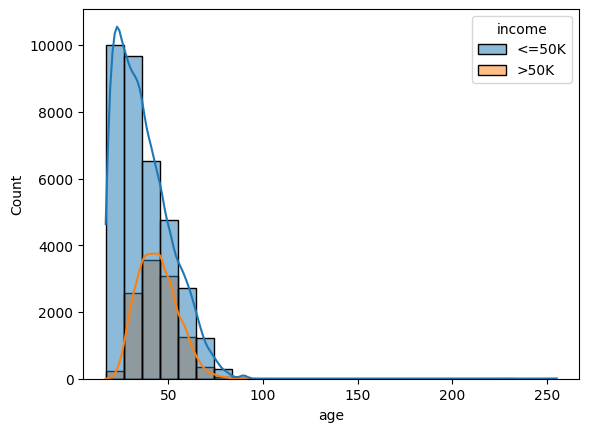

In [67]:
#Combine X_train_res and y_train_res into one temporary DataFrame for plotting
df_smote = X_train_imbalance.copy()
df_smote["Target"] = y_train_df

sns.histplot(data=adult_df,x='age',hue='income',bins=25, kde=True)
plt.show()

In [71]:
adult_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48817 entries, 0 to 48816
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             46375 non-null  float64
 1   workclass       45455 non-null  object 
 2   fnlwgt          48817 non-null  int64  
 3   education       48817 non-null  object 
 4   education-num   48817 non-null  int64  
 5   marital-status  48817 non-null  object 
 6   occupation      45460 non-null  object 
 7   relationship    48817 non-null  object 
 8   race            48817 non-null  object 
 9   sex             48817 non-null  object 
 10  capital-gain    48817 non-null  int64  
 11  capital-loss    48817 non-null  int64  
 12  hours-per-week  46375 non-null  float64
 13  native-country  46112 non-null  object 
 14  income          48817 non-null  object 
dtypes: float64(2), int64(4), object(9)
memory usage: 5.6+ MB


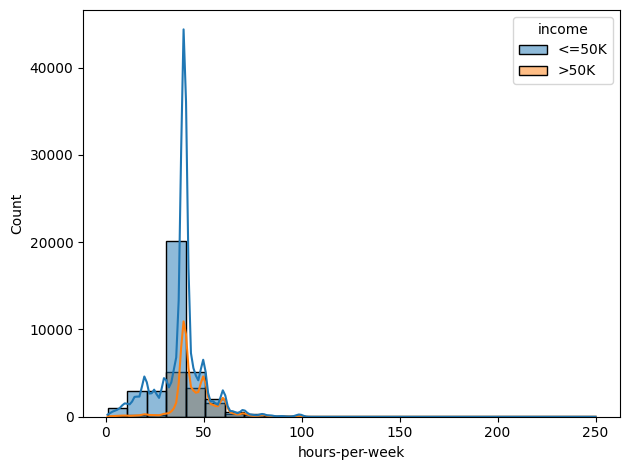

In [72]:
df_smote = X_train_imbalance.copy()
df_smote["Target"] = y_train_df

sns.histplot(data=adult_df,x='hours-per-week',hue='income',bins=25, kde=True)
plt.tight_layout()
plt.show()

In [ ]:
df_smote = X_train_imbalance.copy()
df_smote["Target"] = y_train_df

sns.histplot(data=df_smote,x='age',hue='Target',bins=25, kde=True)
plt.show()

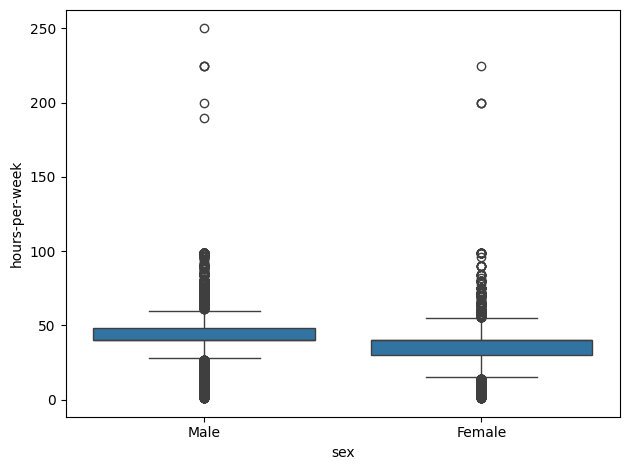

In [79]:
df_smote = X_train_imbalance.copy()
df_smote["Target"] = y_train_df

sns.boxplot(data=adult_df,x='sex',y='hours-per-week')
plt.tight_layout()
plt.show()

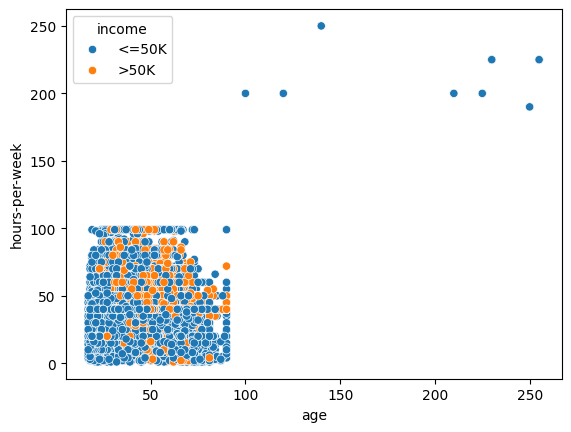

In [89]:
sns.scatterplot(data=adult_df,x='age',y='hours-per-week',hue="income")
plt.show()

The target variable is heavily imbalanced, with only a small proportion of individuals earning more than $50K. Analyzing age against income shows that higher earners (>50K) tend to be older. Also a small amount of people work less than 50 hour-per-week,earn inome>50.